# Huber Regressor (Robust Loss) — Milestone M6a

**Model**: `Huber` (`huber`)  
**Milestone**: M6a — Linear & Statistical Models  
**Evaluated Problems**:
- **S1**: Pavagada Solar Generation (1-hour ahead)
- **S24**: Pavagada Solar Generation (24-hours ahead / Day-Ahead)
- **D1**: Karnataka Grid Demand (1-hour ahead)
- **D24**: Karnataka Grid Demand (24-hours ahead / Day-Ahead)

### Mathematical Formulation & Purpose
Robust regression model that transitions from quadratic loss for small residuals to linear loss for large outliers. Ensures model parameters remain resilient to extreme grid anomalies, sudden solar cloud ramps, and curtailments.

$$L_\epsilon(r) = \begin{cases} \frac{1}{2}r^2 & \text{for } |r| \le \epsilon \\ \epsilon(|r| - \frac{1}{2}\epsilon) & \text{otherwise} \end{cases} \quad (\epsilon = 1.35)$$


In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Ensure project root is accessible from models/linear_statistical/
project_root = Path.cwd().parent.parent if Path.cwd().name == "linear_statistical" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
import src.models_stat as ms

print("Project root successfully linked:", project_root)


Project root successfully linked: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT


## 1. Load M4 Processed Datasets & Train Model
In strict compliance with roadmap rules:
- Data is loaded directly from `data/processed/` without modifying features or preprocessing.
- Training set: `2021-03-08` → `2024-12-31`
- Validation set: `2025-01-01` → `2025-12-31`
- Test set: `2026-01-01` → `2026-02-28` (**Quarantined - Never used for training or model selection**)


In [2]:
model_name = "huber"
model_kwargs = {'epsilon': 1.35, 'max_iter': 1000}
problems = ["S1", "S24", "D1", "D24"]

results = []
for pid in problems:
    res = ms.train_and_eval_linear_model(
        model_name=model_name,
        problem_id=pid,
        model_kwargs=model_kwargs,
        use_scaled=True
    )
    # Generate and save diagnostic figures
    saved_figs = ms.plot_model_diagnostics(res)
    results.append(res)


LOADING PROCESSED DATASET FOR PROBLEM: S1
Target: solar_power_mw | Horizon: 1h
Using Scaled Features: True
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_S1_scaled.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_S1.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_S1_scaled.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_S1.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_S1_scaled.parquet (QUARANTINED - NOT TOUCHED)
Loaded Train: 33,480 rows (2021-03-08 00:00:00 to 2024-12-31 23:00:00)
Loaded Val:   8,760 rows (2025-01-01 00:00:00 to 2025-12-31 23:00:00)
Test Available: X_test_S1_scaled.parquet (44 features, strictly quarantined)

Training HUBER on S1 (44 features)...


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\.venv\Lib\site-packages\sklearn\linear_model\_huber.py:348: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


Saved model artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\huber_S1.joblib


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\models_stat.py:271: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="coefficient", y="feature", data=coef_df, palette=colors)


LOADING PROCESSED DATASET FOR PROBLEM: S24
Target: solar_power_mw | Horizon: 24h
Using Scaled Features: True
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_S24_scaled.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_S24.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_S24_scaled.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_S24.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_S24_scaled.parquet (QUARANTINED - NOT TOUCHED)
Loaded Train: 33,480 rows (2021-03-08 00:00:00 to 2024-12-31 23:00:00)
Loaded Val:   8,760 rows (2025-01-01 00:00:00 to 2025-12-31 23:00:00)
Test Available: X_test_S24_scaled.parquet (41 features, strictly quarantined)

Training HUBER on S24 (41 features)...


Saved model artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\huber_S24.joblib


... (3 outputs left out)

C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\models_stat.py:271: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="coefficient", y="feature", data=coef_df, palette=colors)


LOADING PROCESSED DATASET FOR PROBLEM: D24
Target: demand_mw | Horizon: 24h
Using Scaled Features: True
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_D24_scaled.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_D24.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_D24_scaled.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_D24.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_D24_scaled.parquet (QUARANTINED - NOT TOUCHED)
Loaded Train: 33,480 rows (2021-03-08 00:00:00 to 2024-12-31 23:00:00)
Loaded Val:   8,760 rows (2025-01-01 00:00:00 to 2025-12-31 23:00:00)
Test Available: X_test_D24_scaled.parquet (41 features, strictly quarantined)

Training HUBER on D24 (41 features)...


Saved model artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\huber_D24.joblib


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\models_stat.py:271: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="coefficient", y="feature", data=coef_df, palette=colors)


## 2. Validation Metrics & Performance Benchmark
Evaluation across all 8 roadmap metrics:
1. **RMSE** (Root Mean Squared Error, MW)
2. **MAE** (Mean Absolute Error, MW)
3. **nMAE** (Normalized MAE, % of 2,050 MW capacity for solar, % of mean for demand)
4. **MAPE** (Demand only, %; omitted for solar to prevent zero division)
5. **sMAPE** (Symmetric MAPE, %)
6. **R²** (Coefficient of Determination)
7. **MBE** (Mean Bias Error, MW)
8. **Skill Score vs Persistence** (% improvement over Milestone M5 baseline floor)


In [3]:
metrics_df = ms.save_and_record_results(results, model_name)
display(metrics_df)



Saved validation predictions to: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\predictions\huber_val_predictions.parquet
Saved validation metrics table to: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\tables\huber_val_metrics.csv


,model,problem,target,horizon,rmse,mae,nmae_pct,mape_pct,smape_pct,r2,mbe,skill_vs_persistence,daylight_rmse,daylight_mae,daylight_nmae_pct
0,huber,S1,solar_power_mw,1h,40.19,11.44,0.56,NaN,6.76,0.9952,5.56,80.96,56.62,22.71,1.11
1,huber,S24,solar_power_mw,24h,50.44,14.10,0.69,NaN,4.68,0.9924,8.31,76.23,71.07,28.00,1.37
2,huber,D1,demand_mw,1h,242.27,185.85,1.48,1.52,1.52,0.9868,-23.73,63.84,NaN,NaN,NaN
3,huber,D24,demand_mw,24h,457.43,350.99,2.79,2.83,2.83,0.9530,-63.49,40.69,NaN,NaN,NaN


## 3. Diagnostic Visualizations
Inspection of prediction tracking, residual distributions, and standardized feature coefficients.



DIAGNOSTIC PLOTS FOR PROBLEM S1


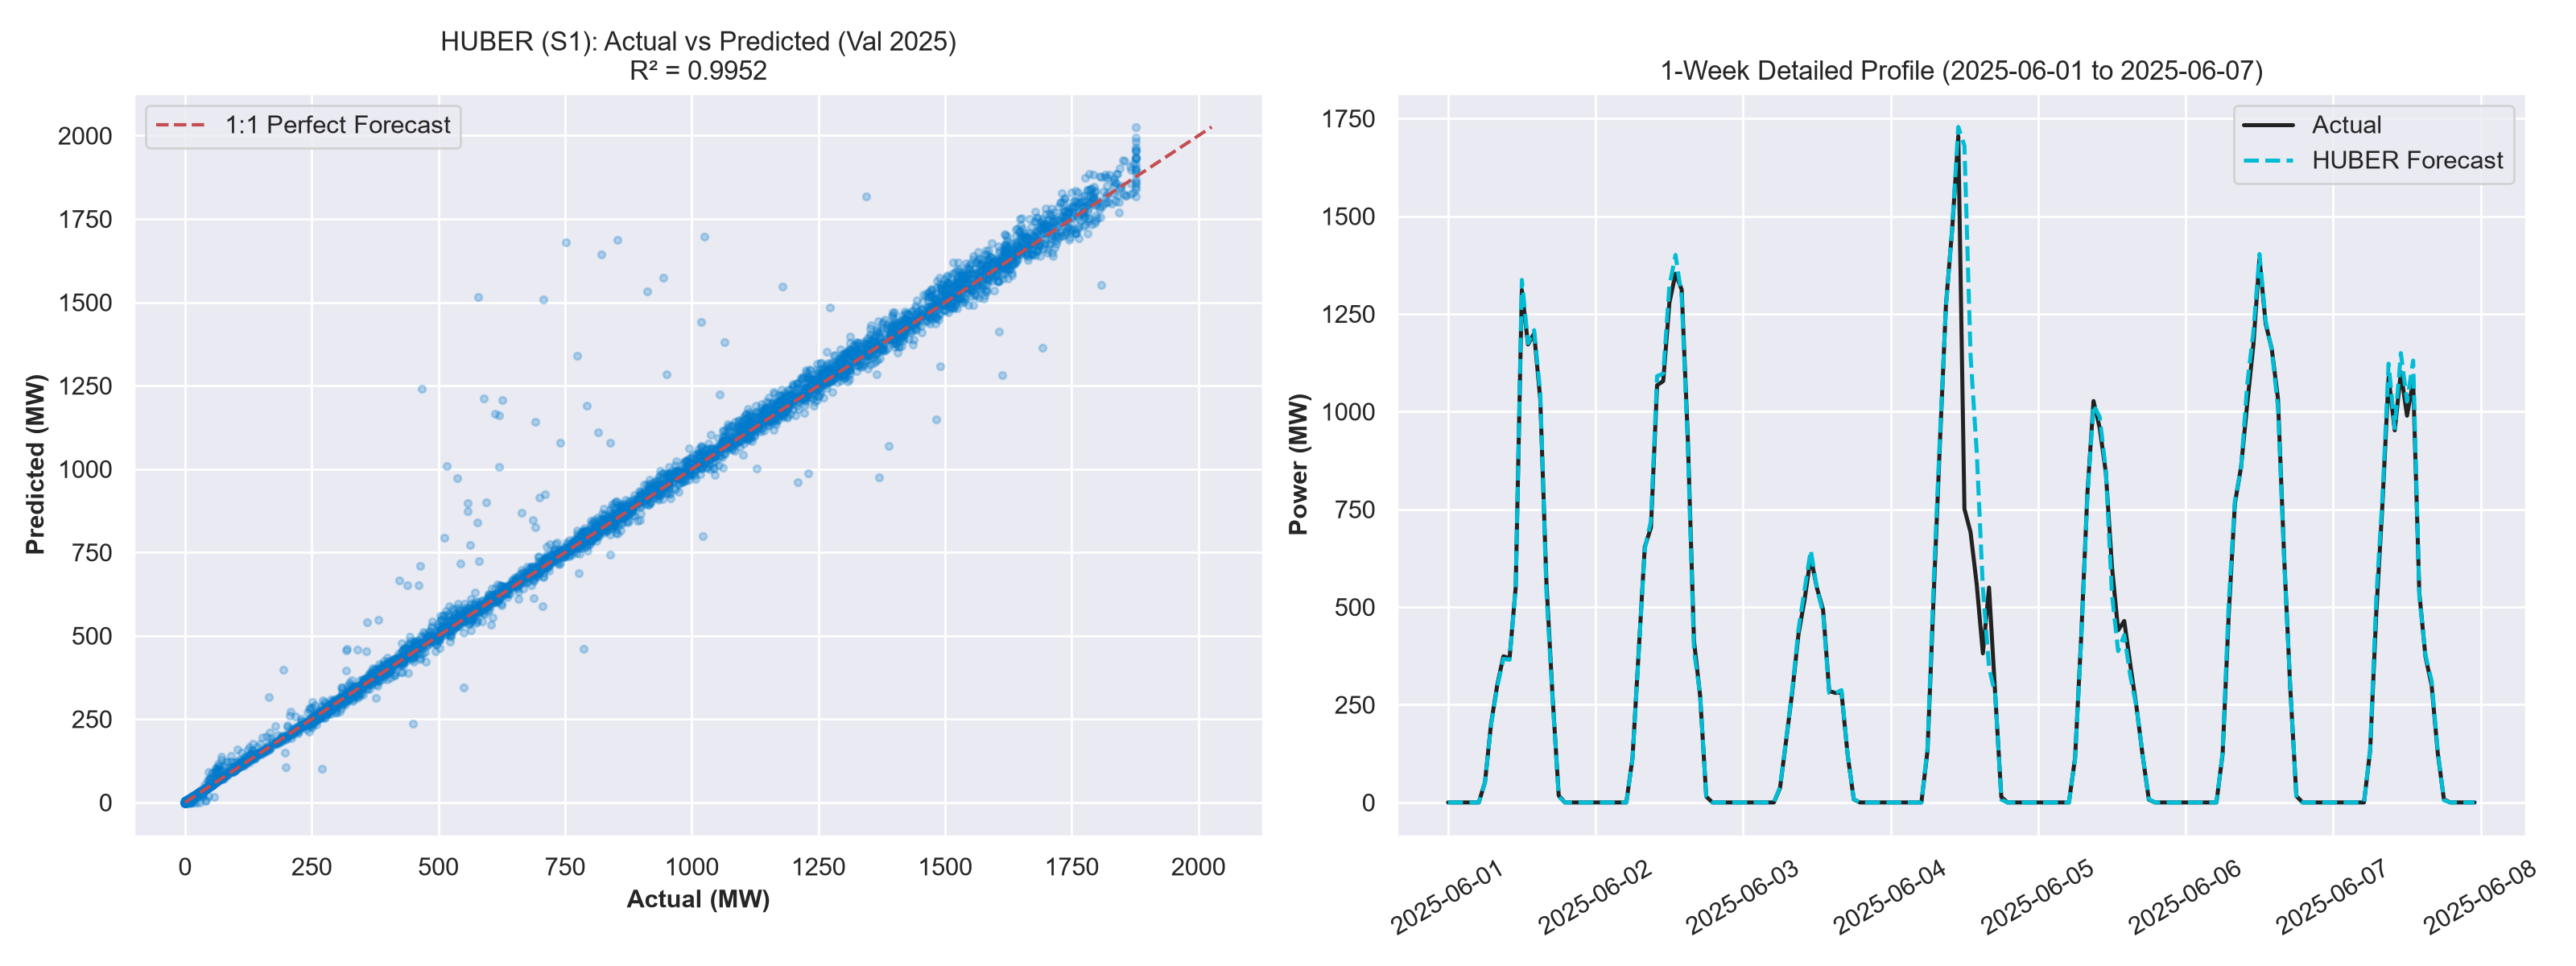

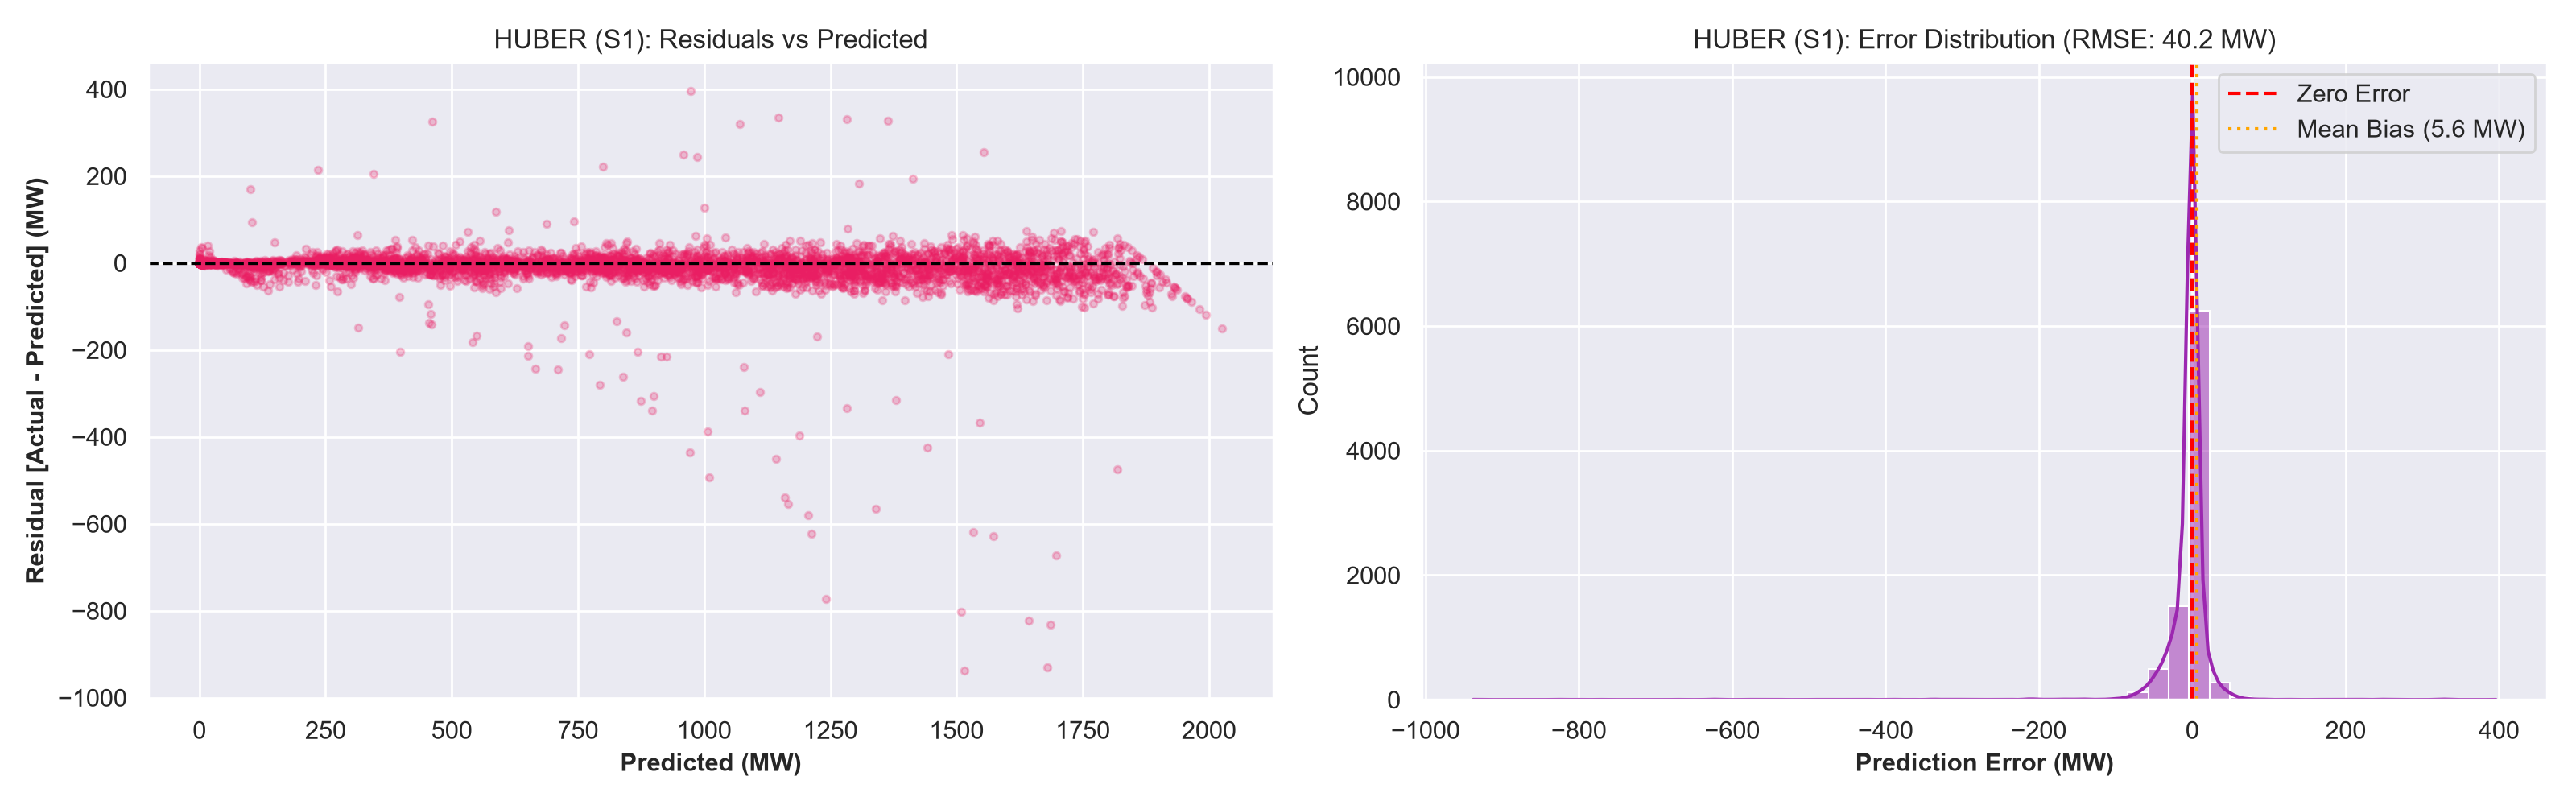

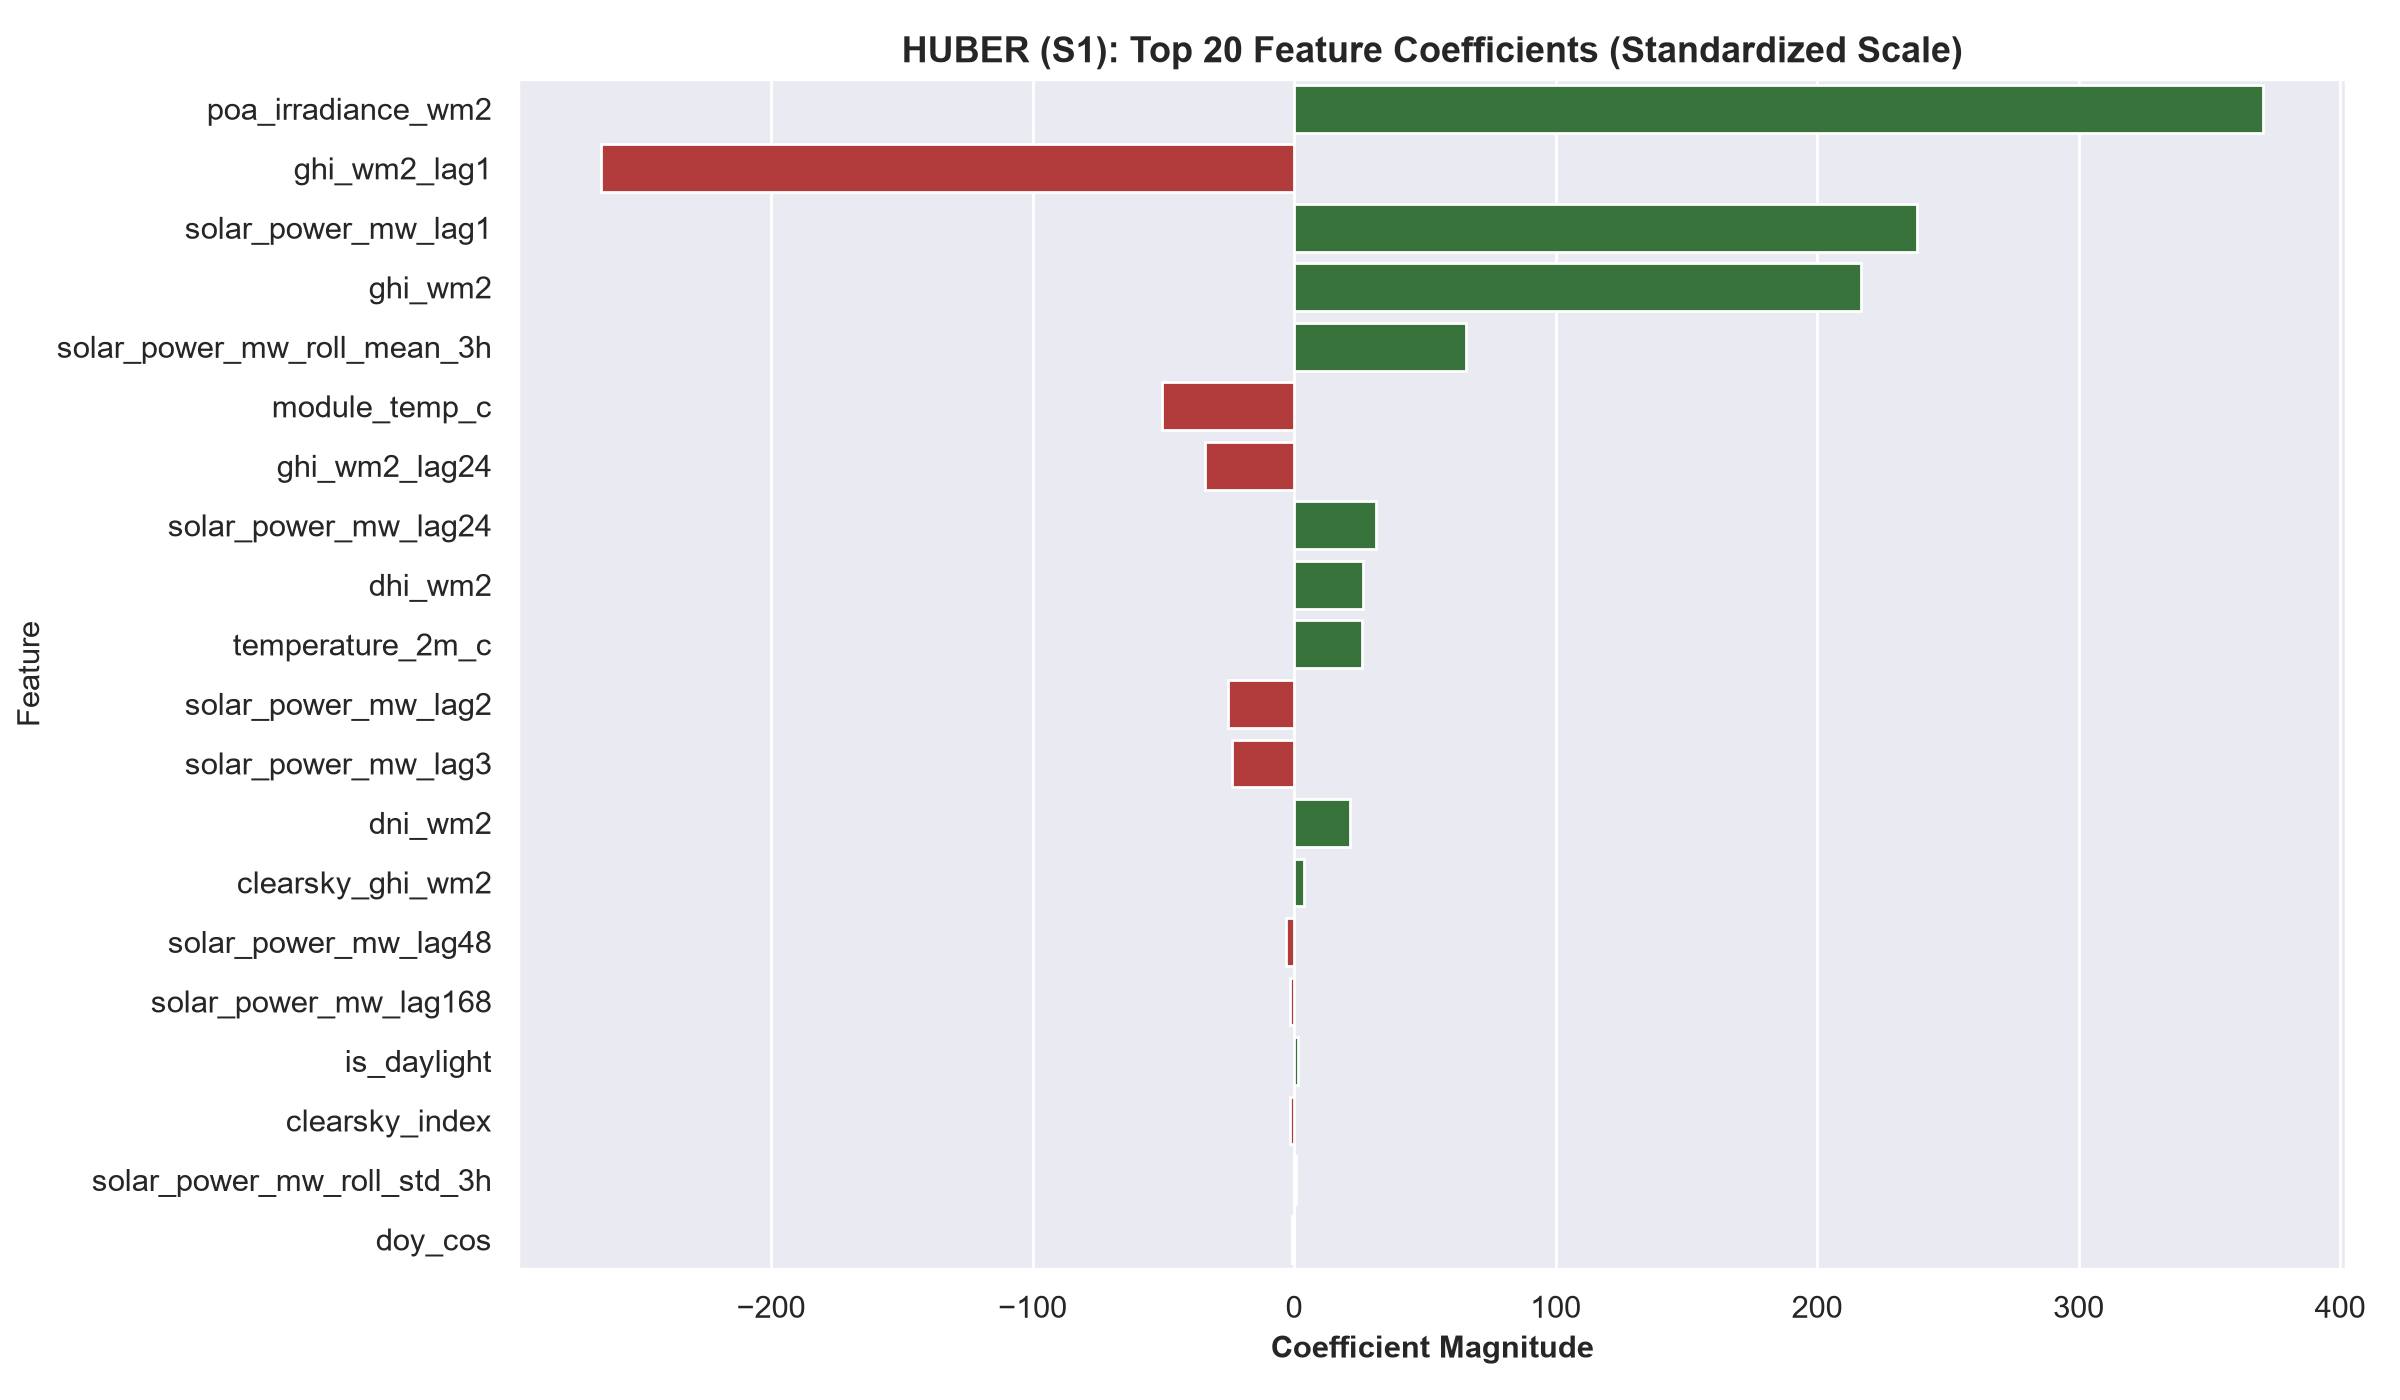


DIAGNOSTIC PLOTS FOR PROBLEM S24


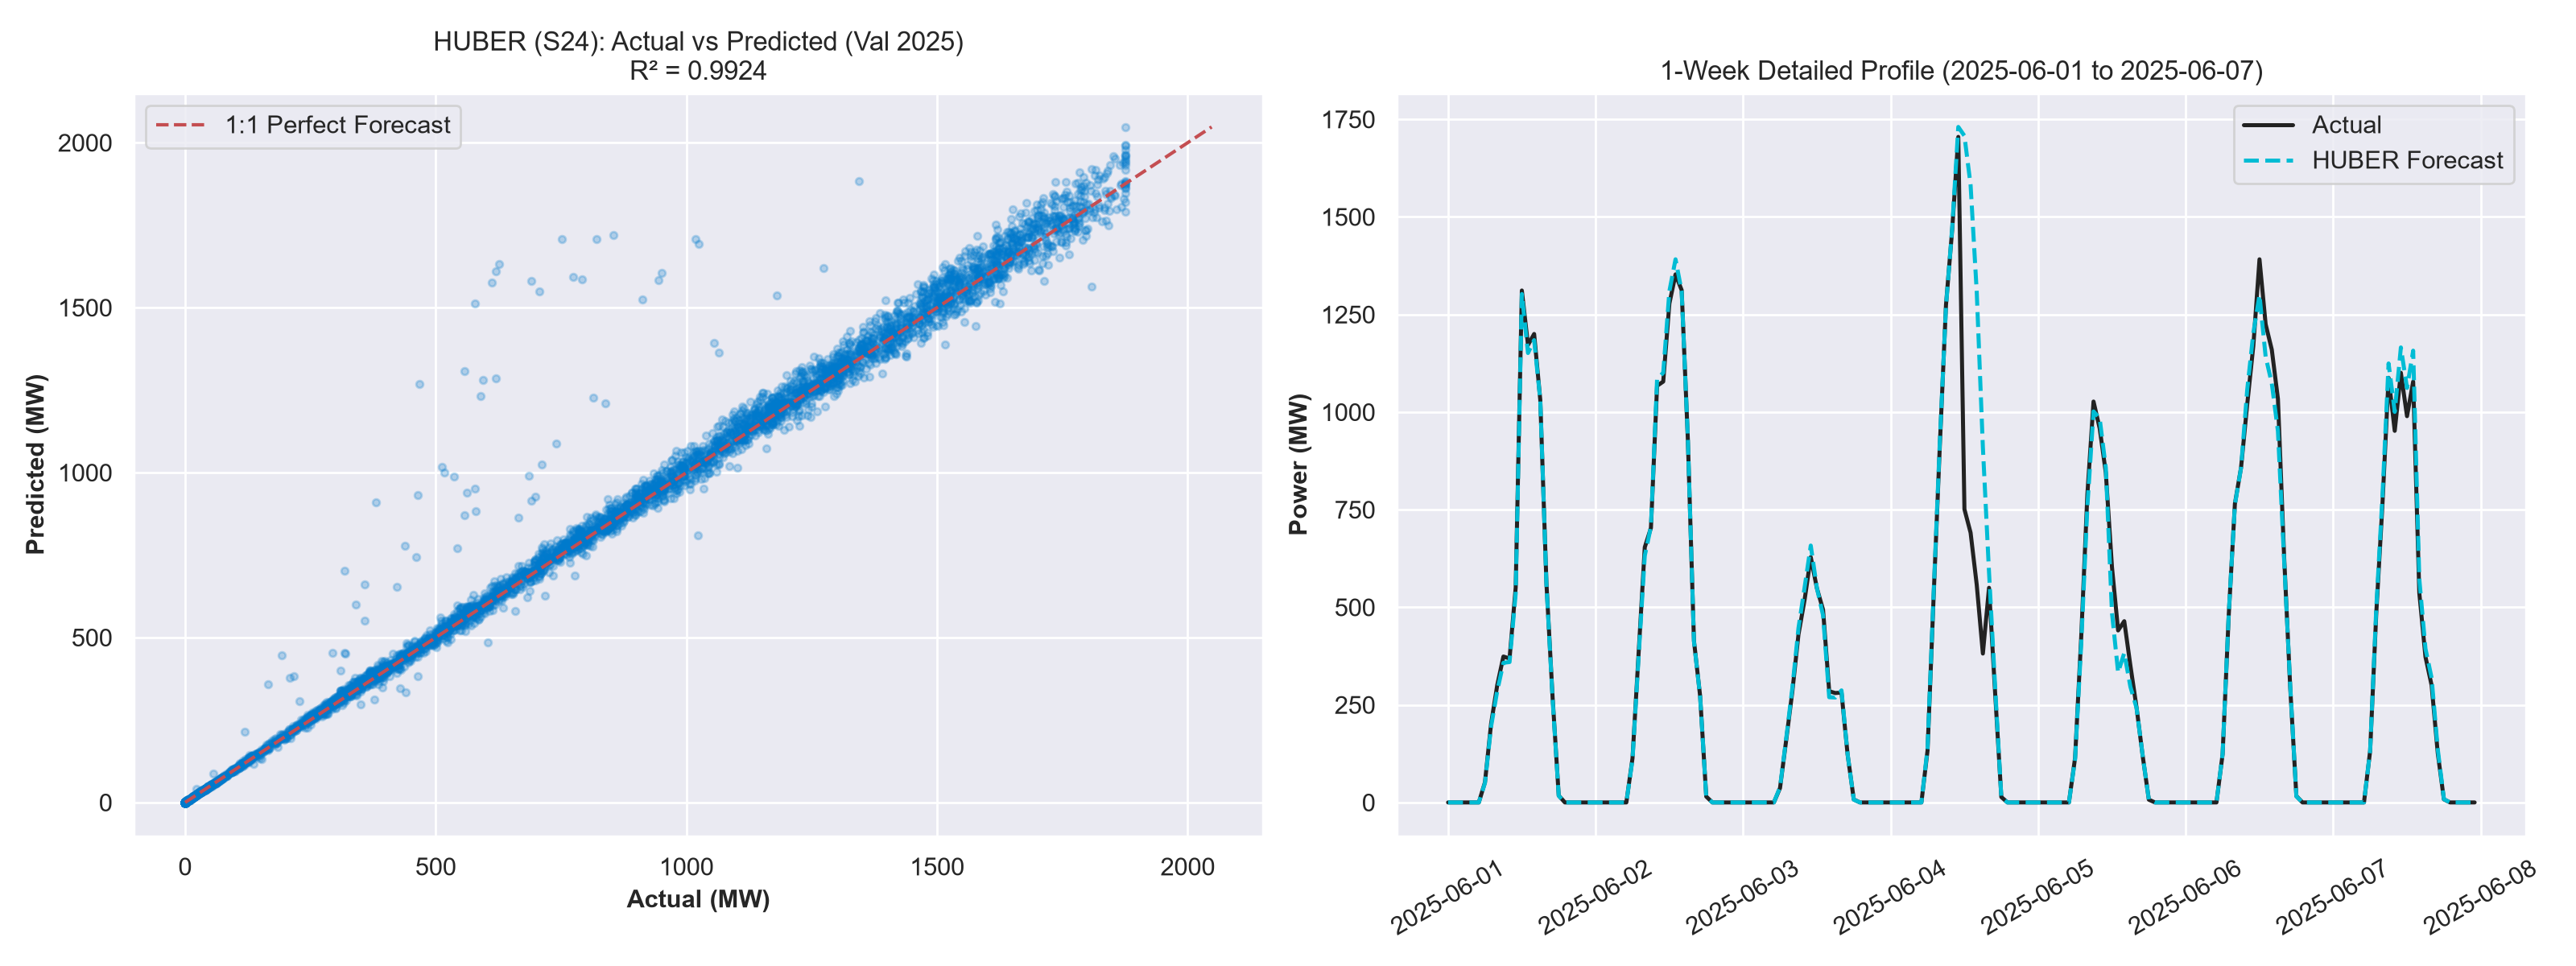

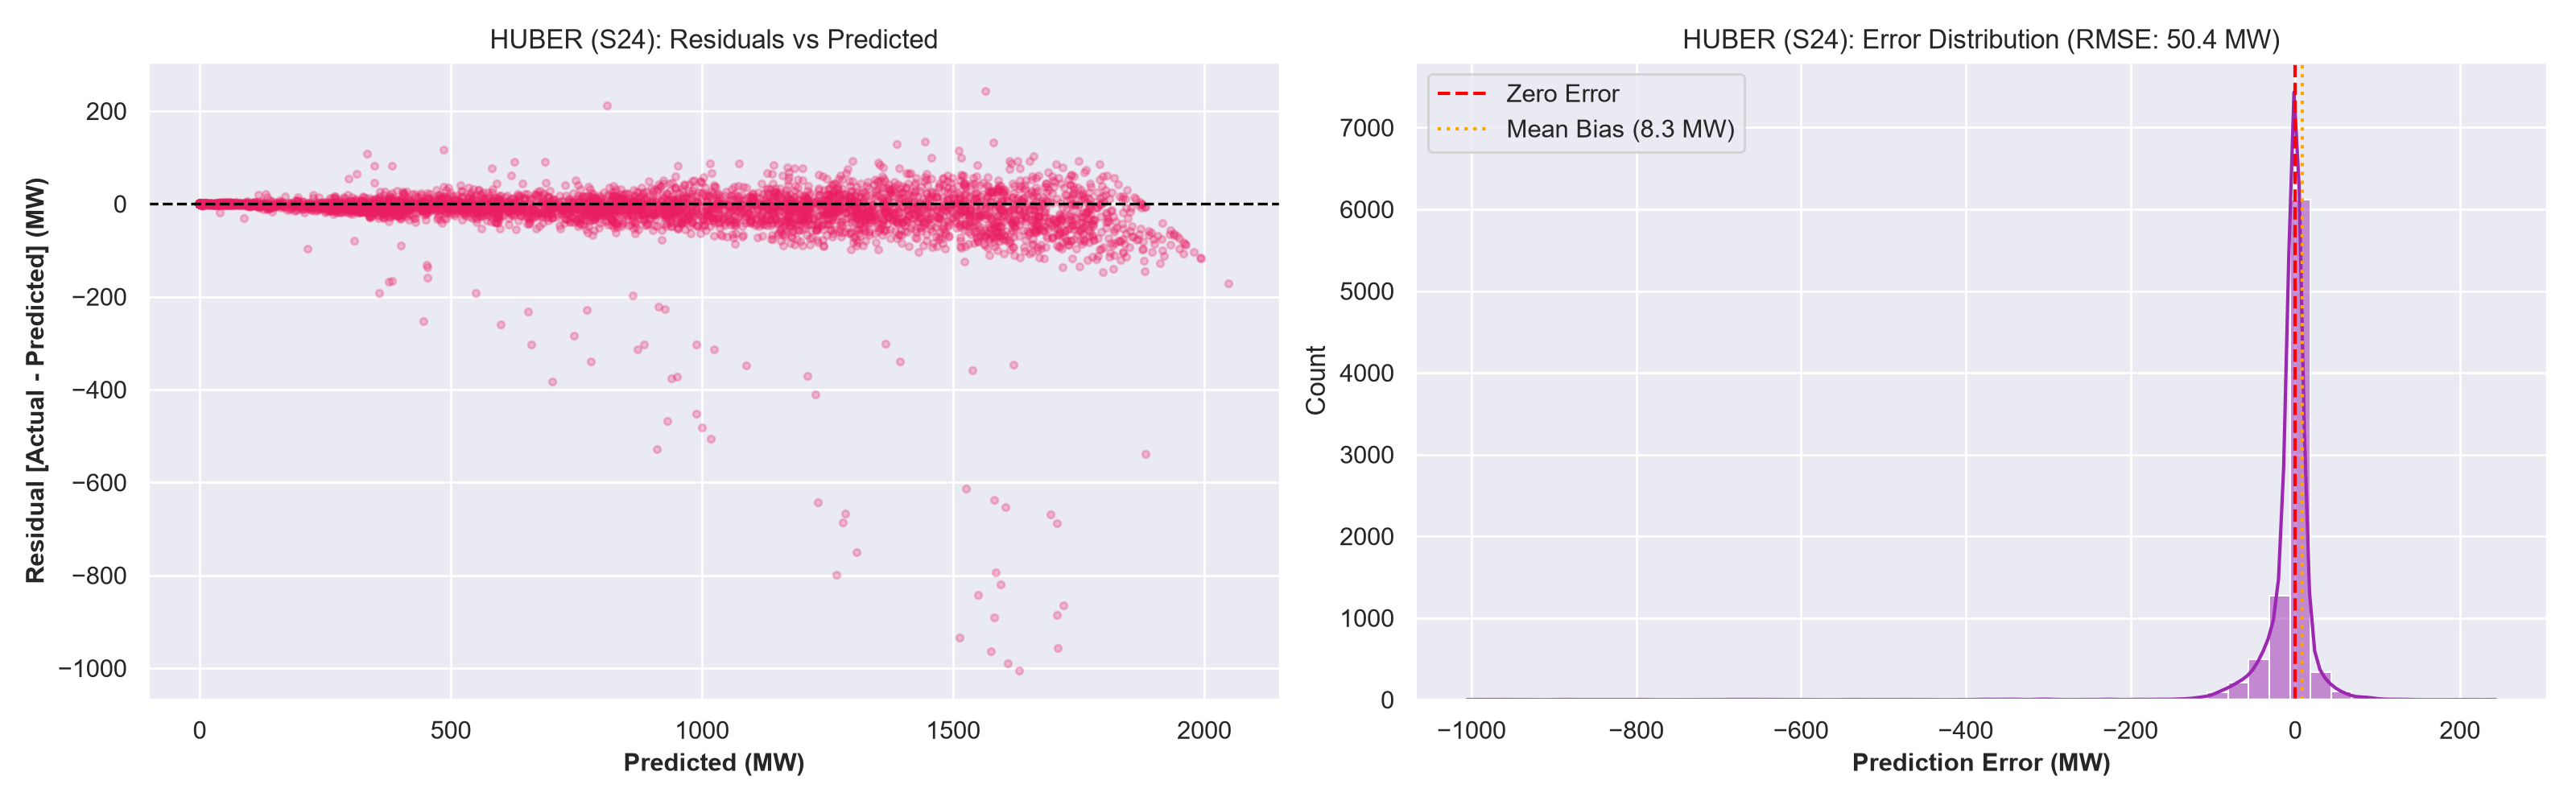

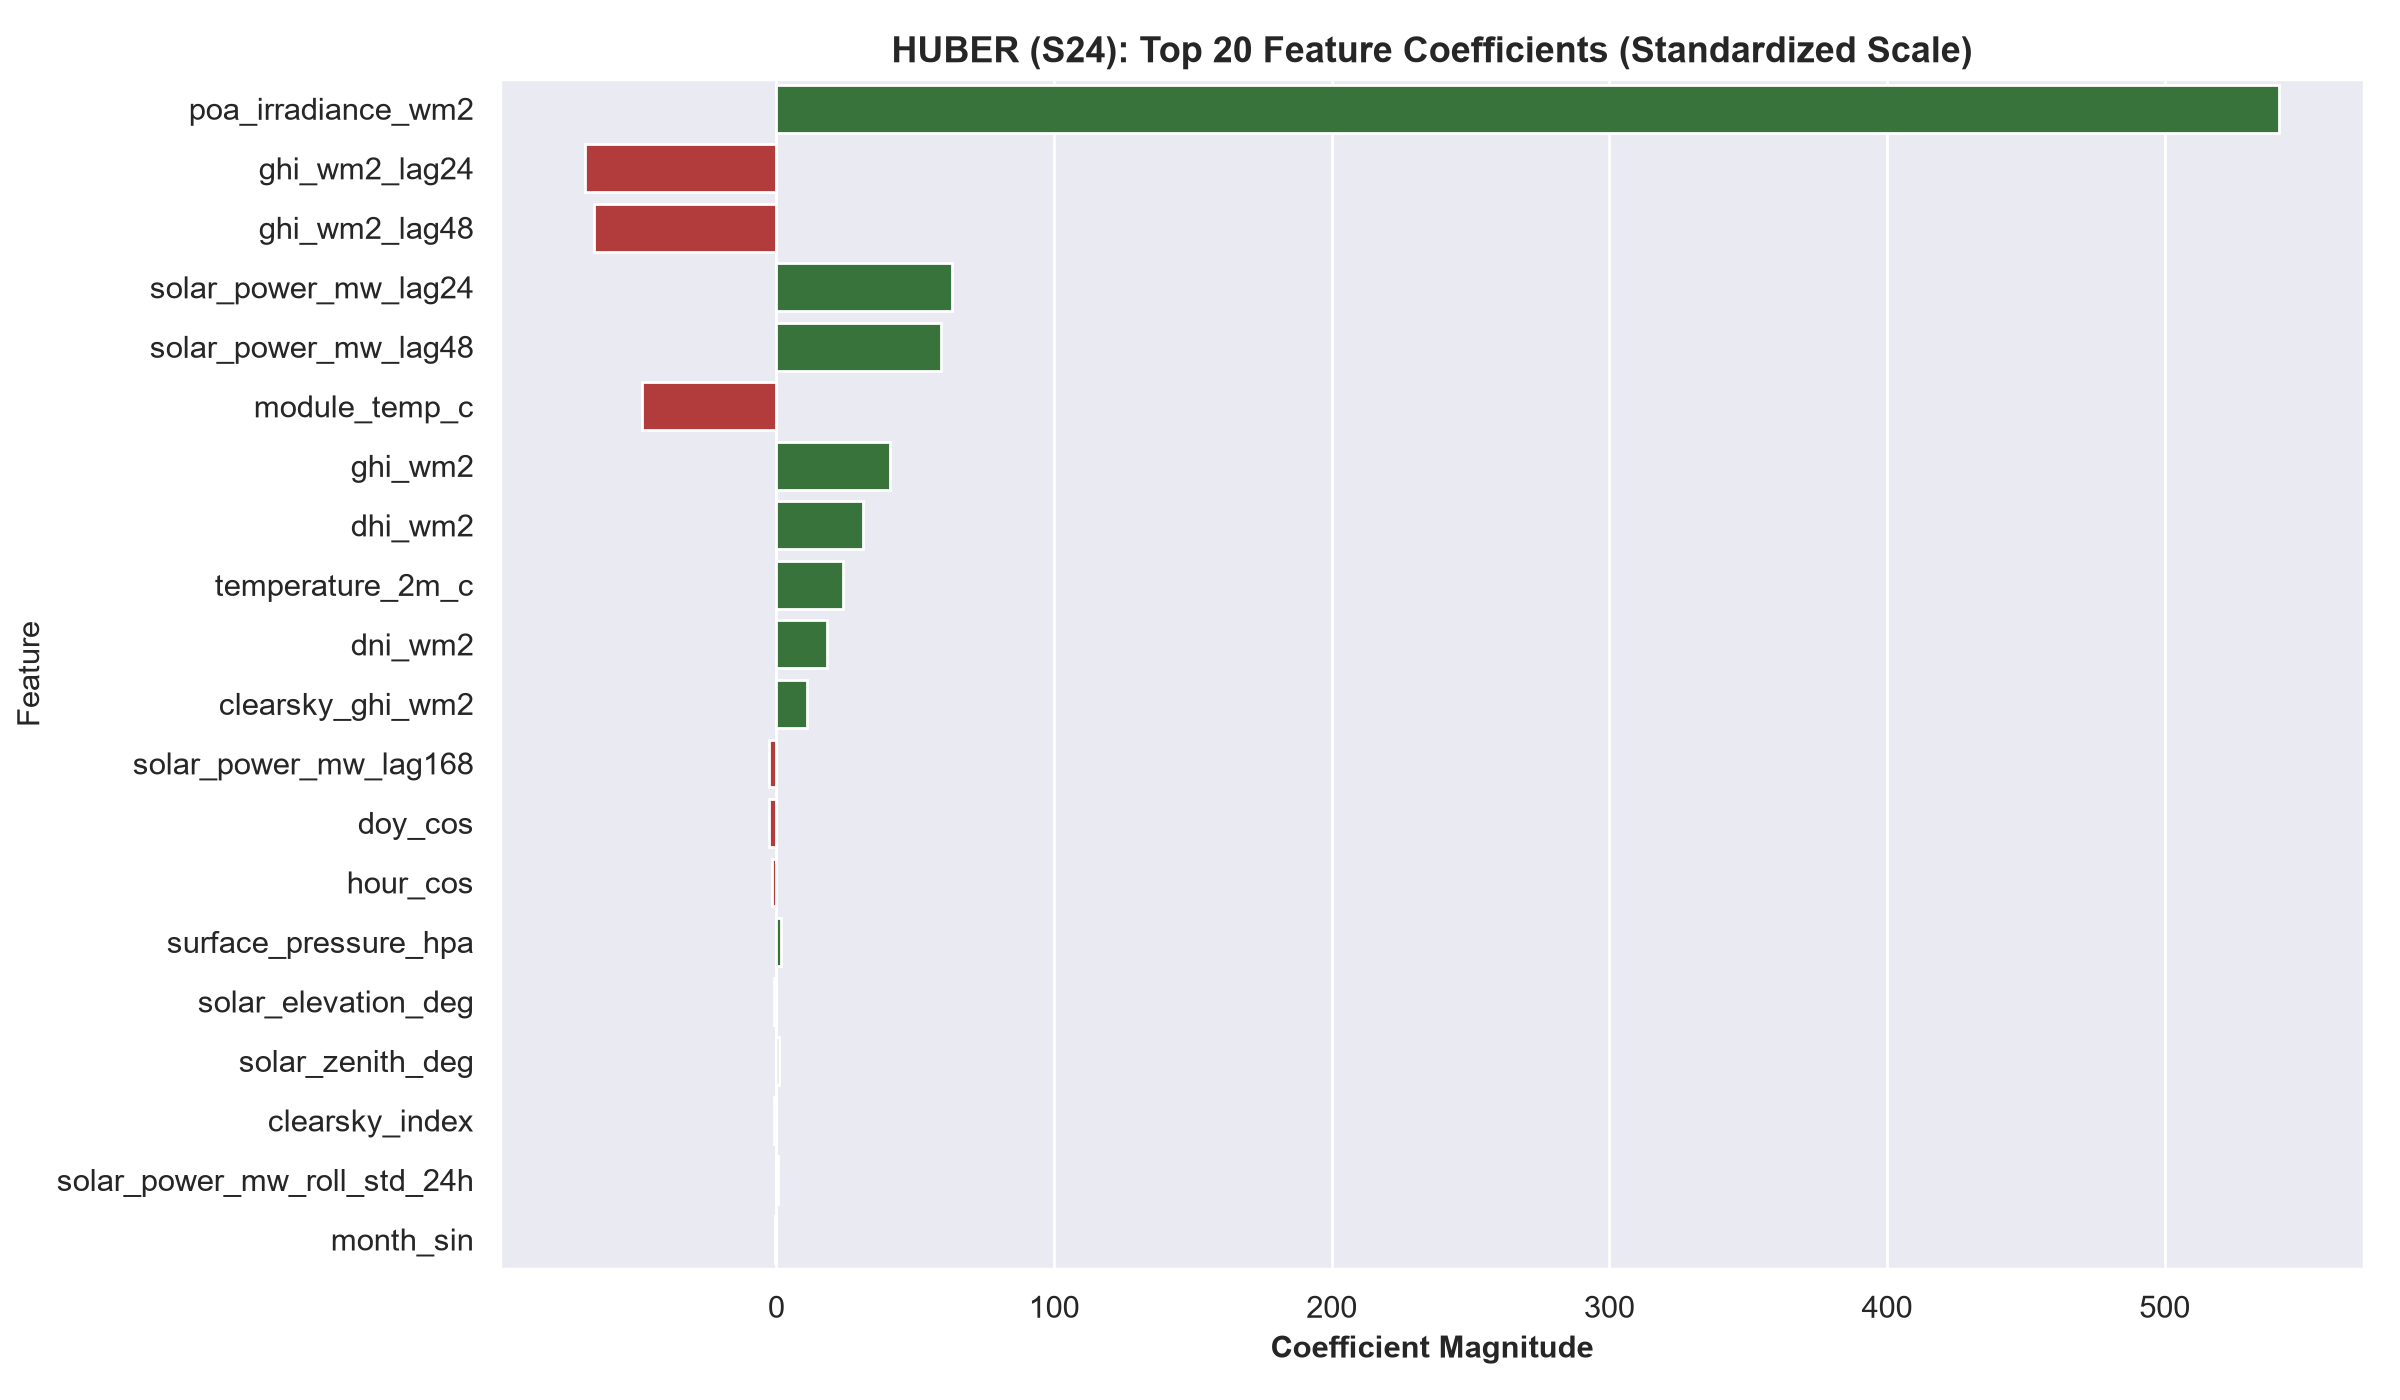


DIAGNOSTIC PLOTS FOR PROBLEM D1


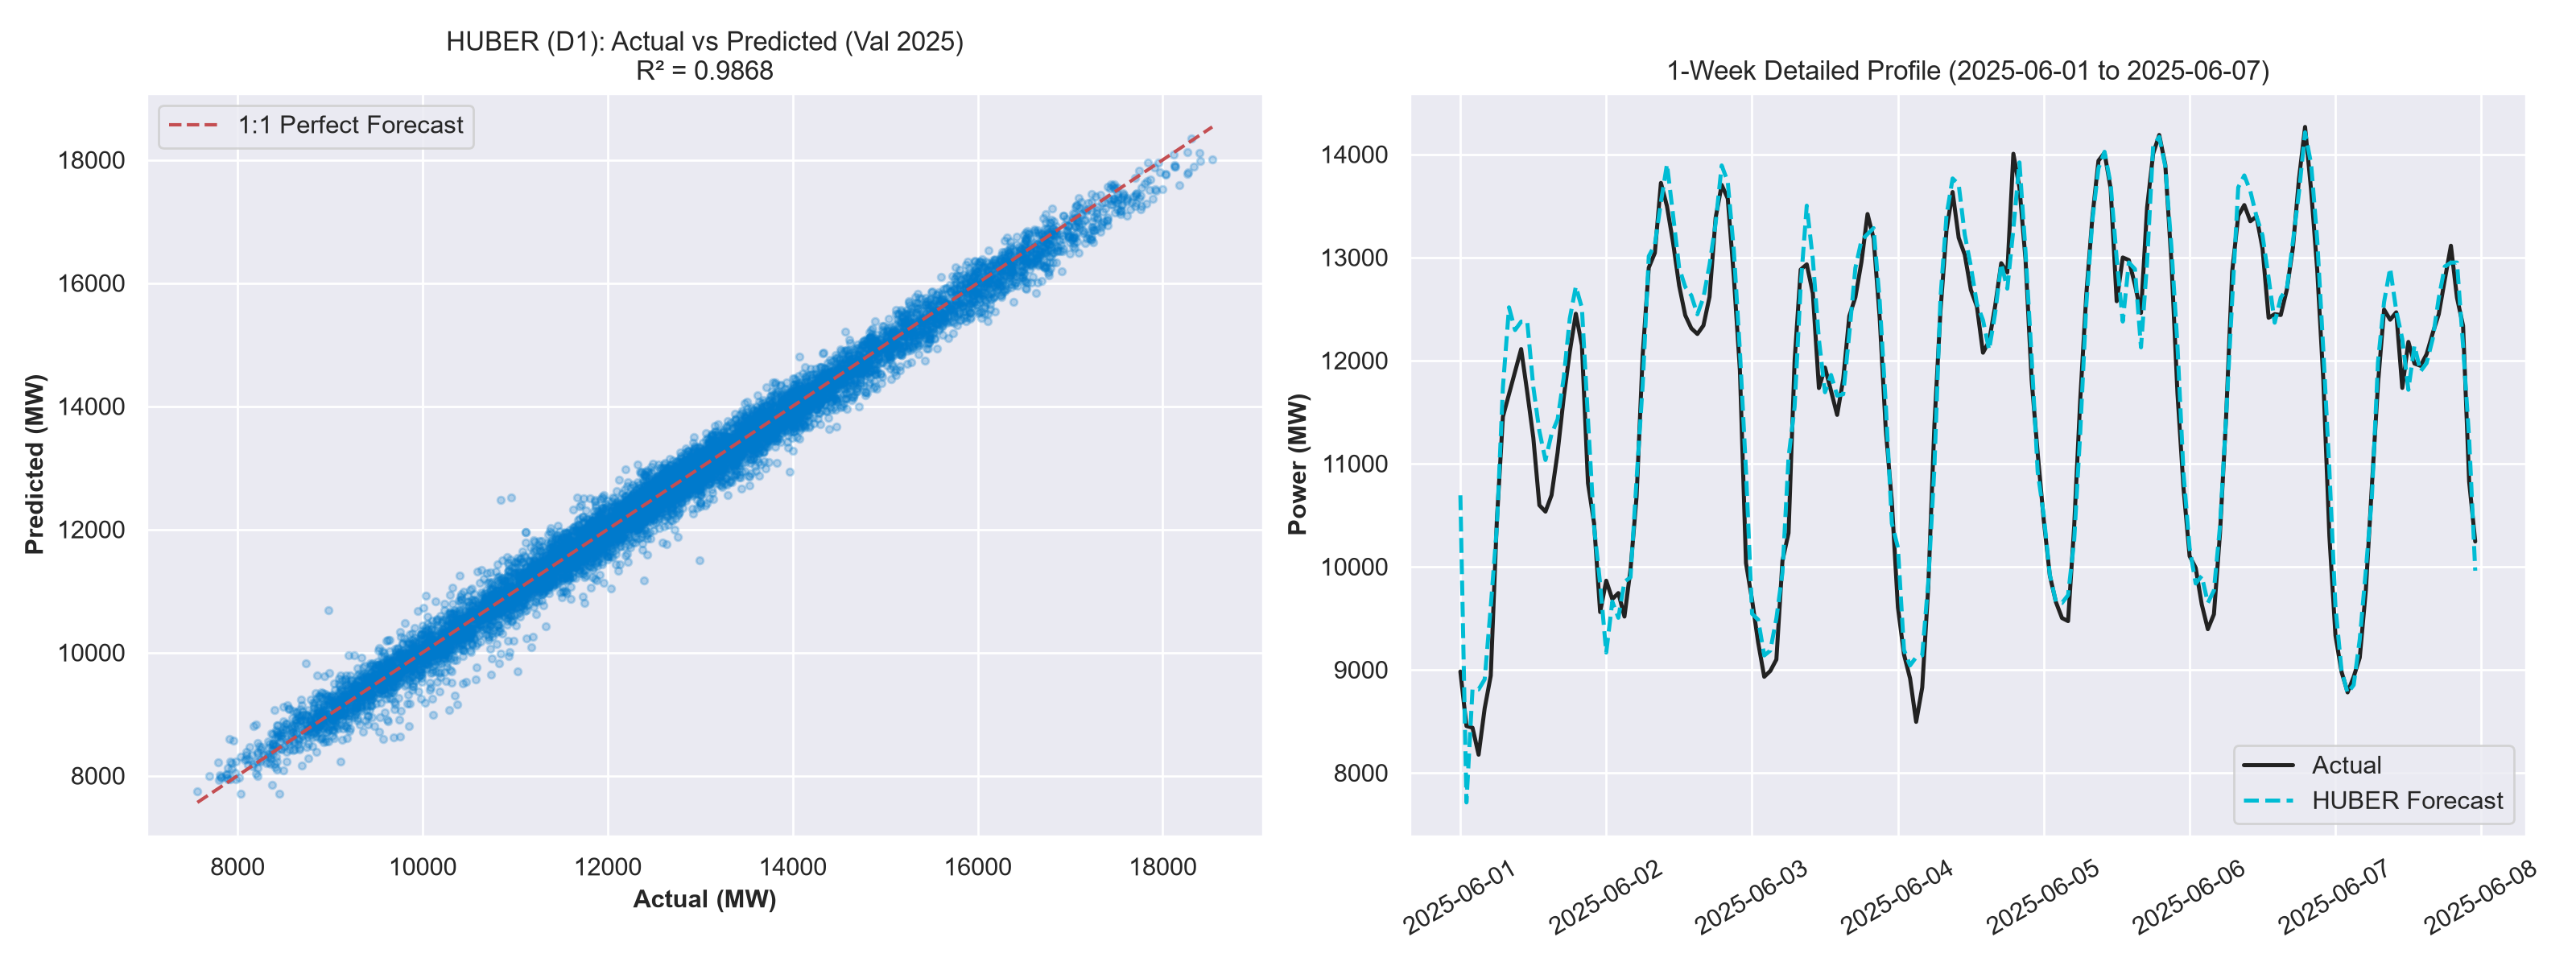

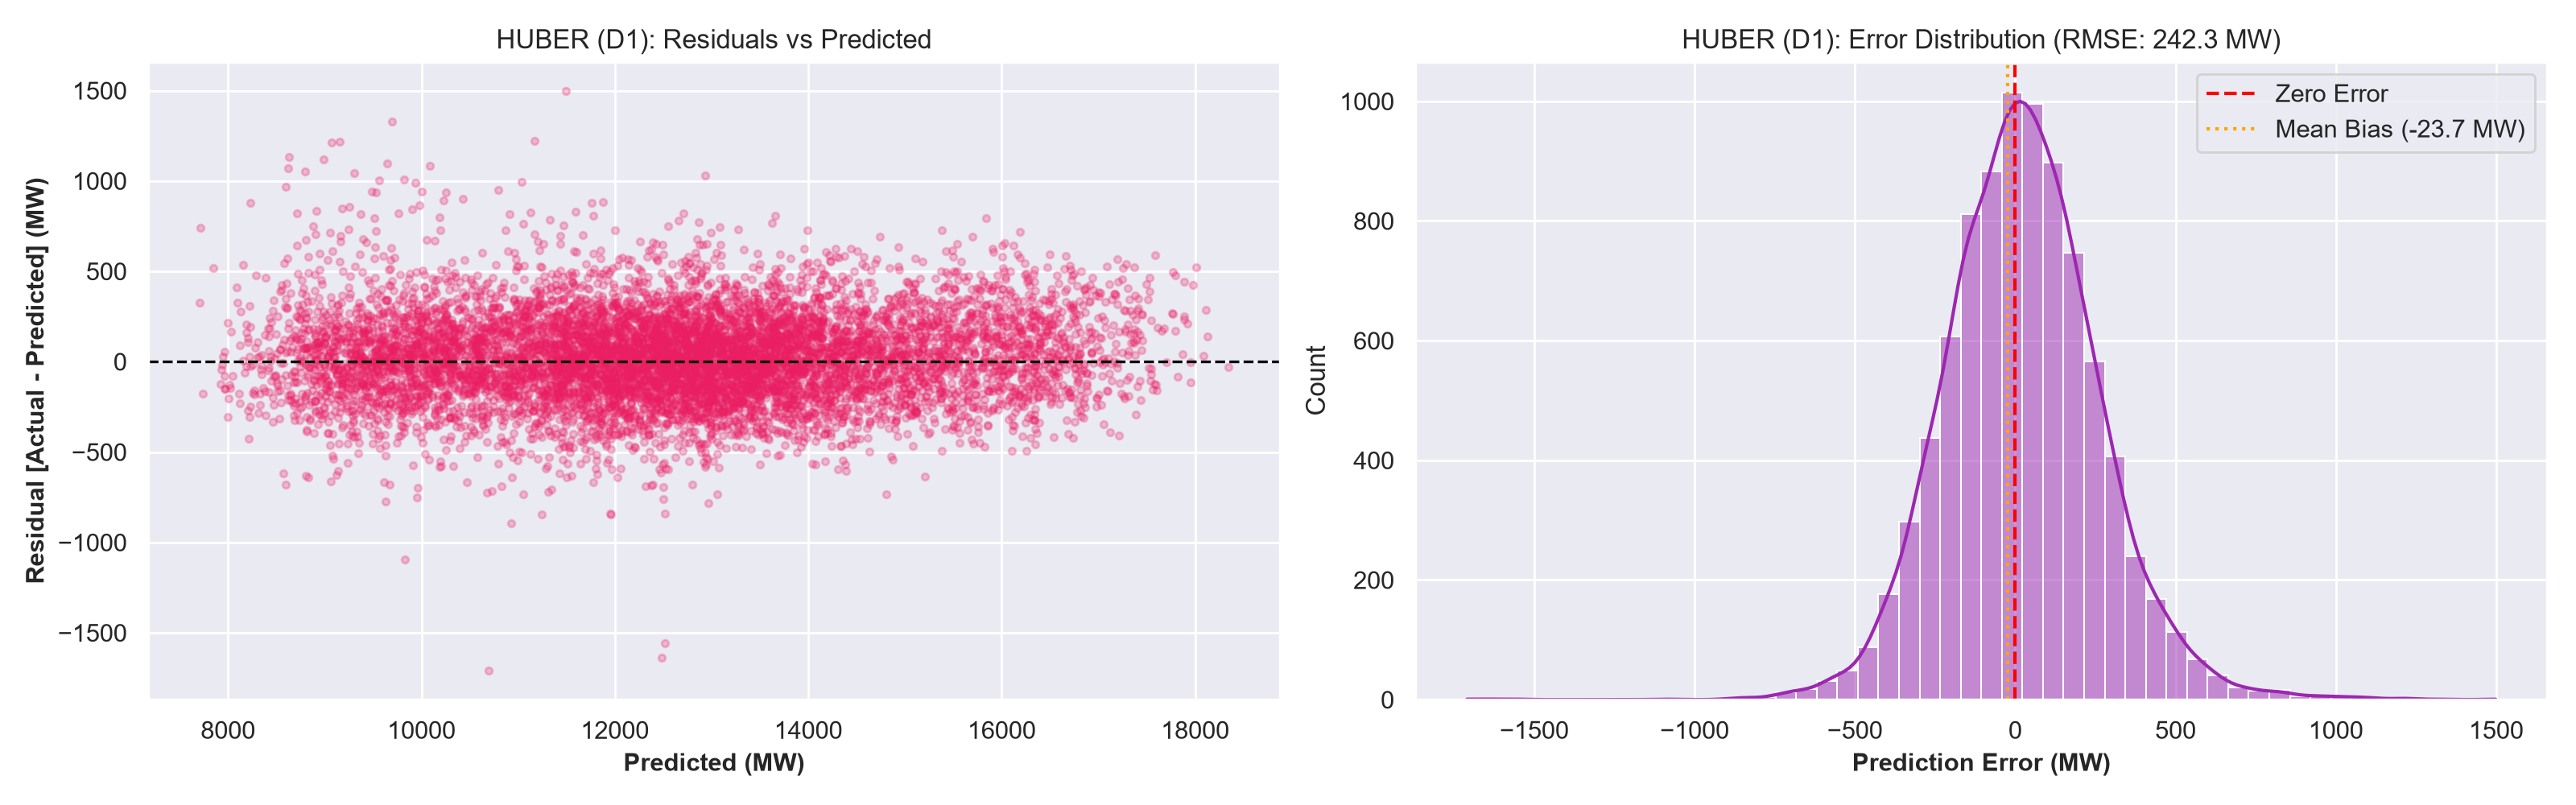

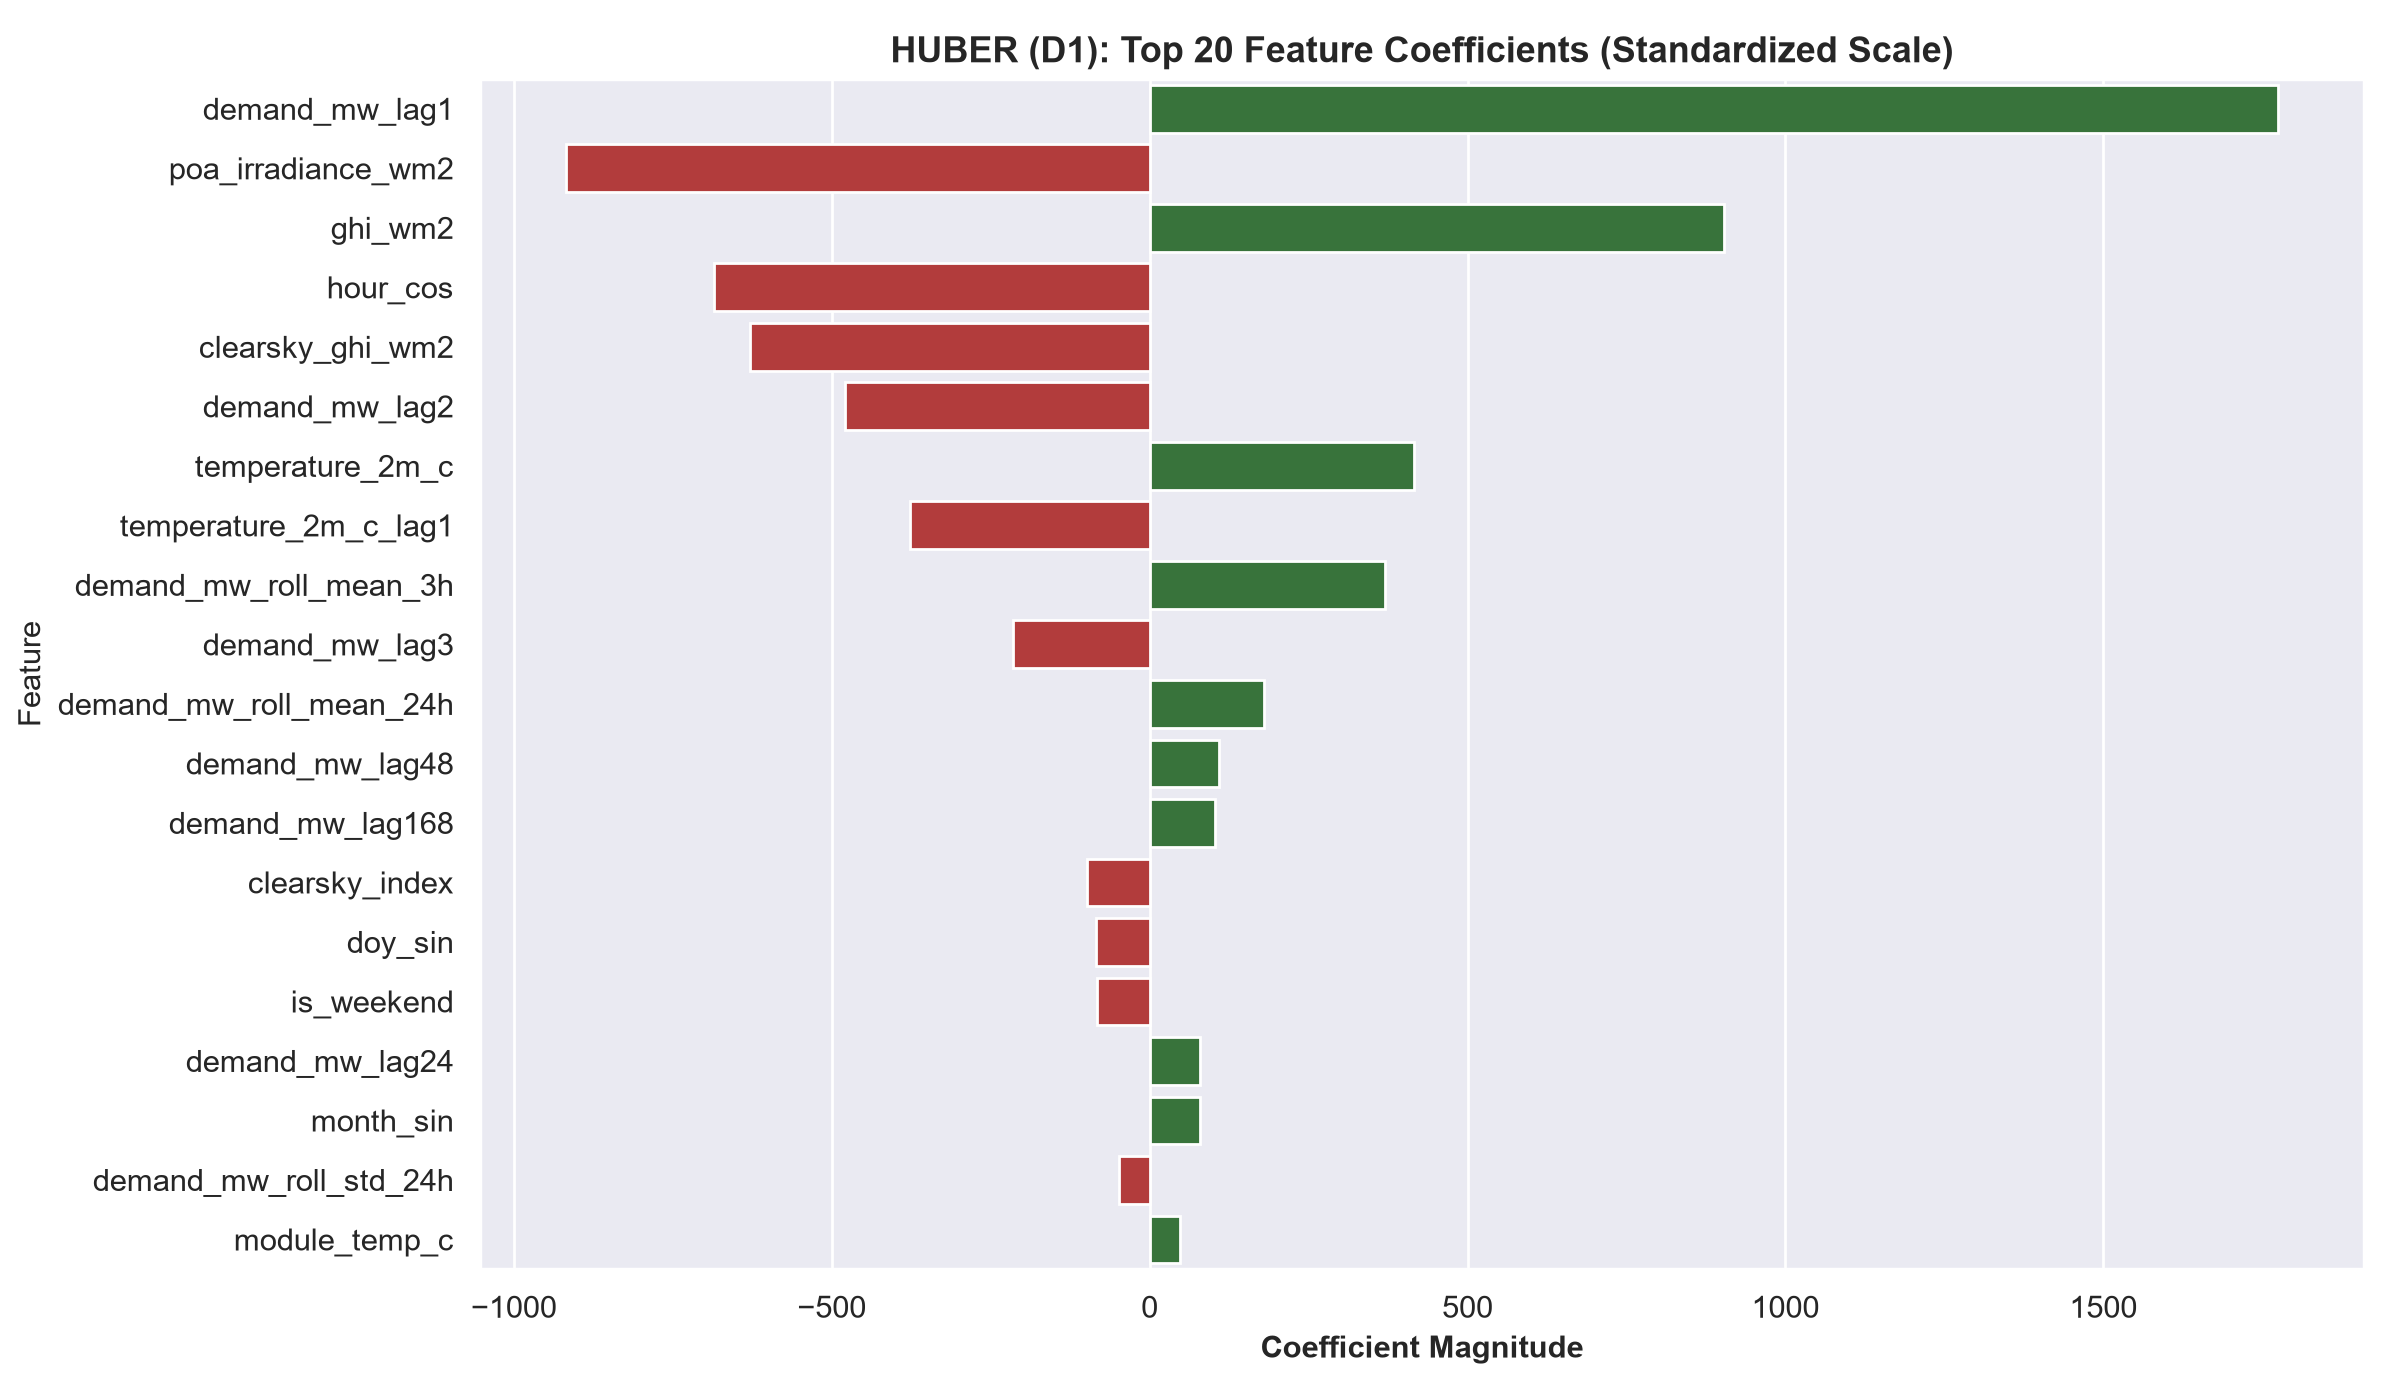


DIAGNOSTIC PLOTS FOR PROBLEM D24


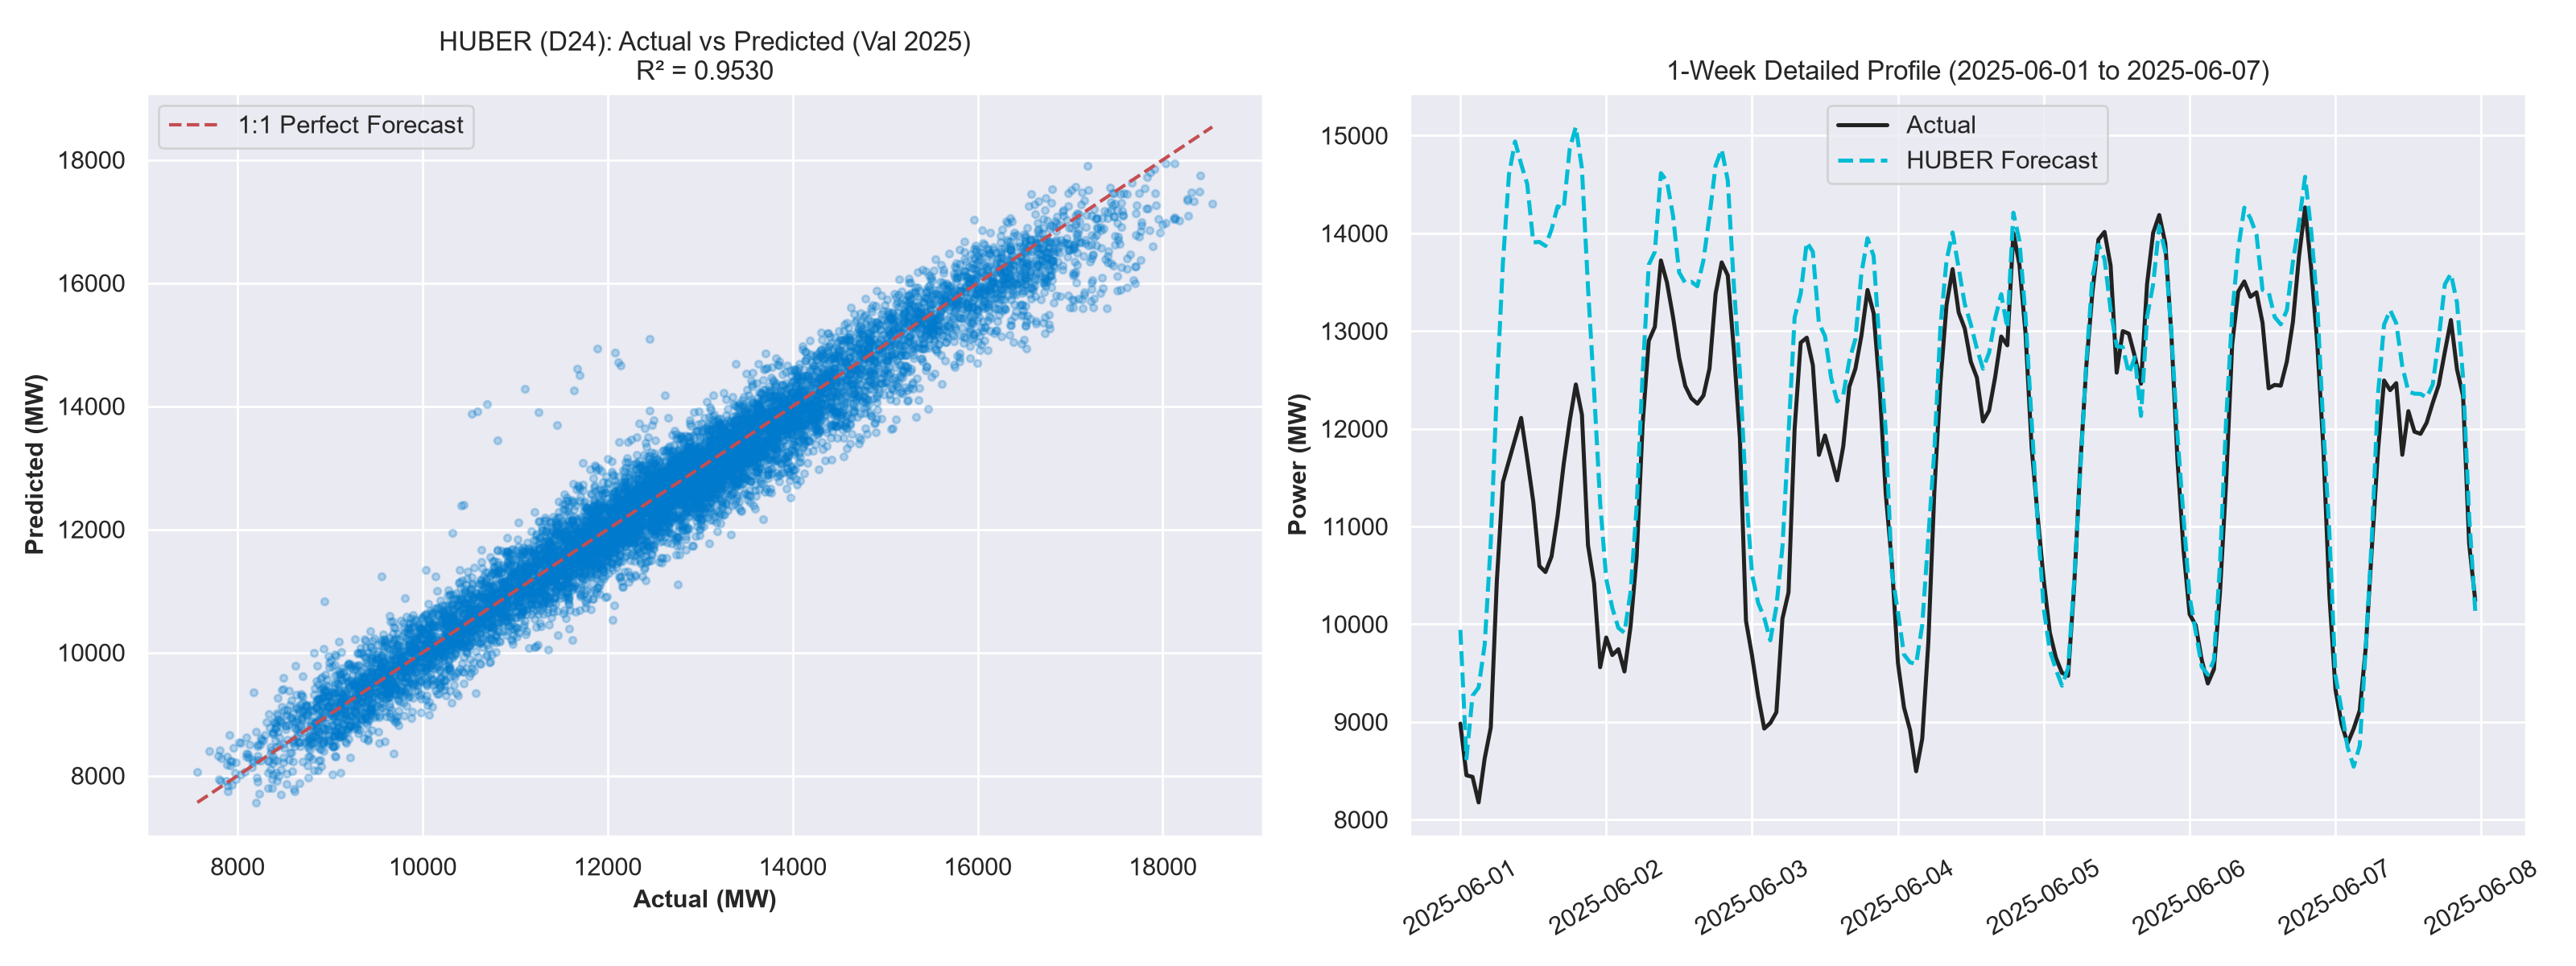

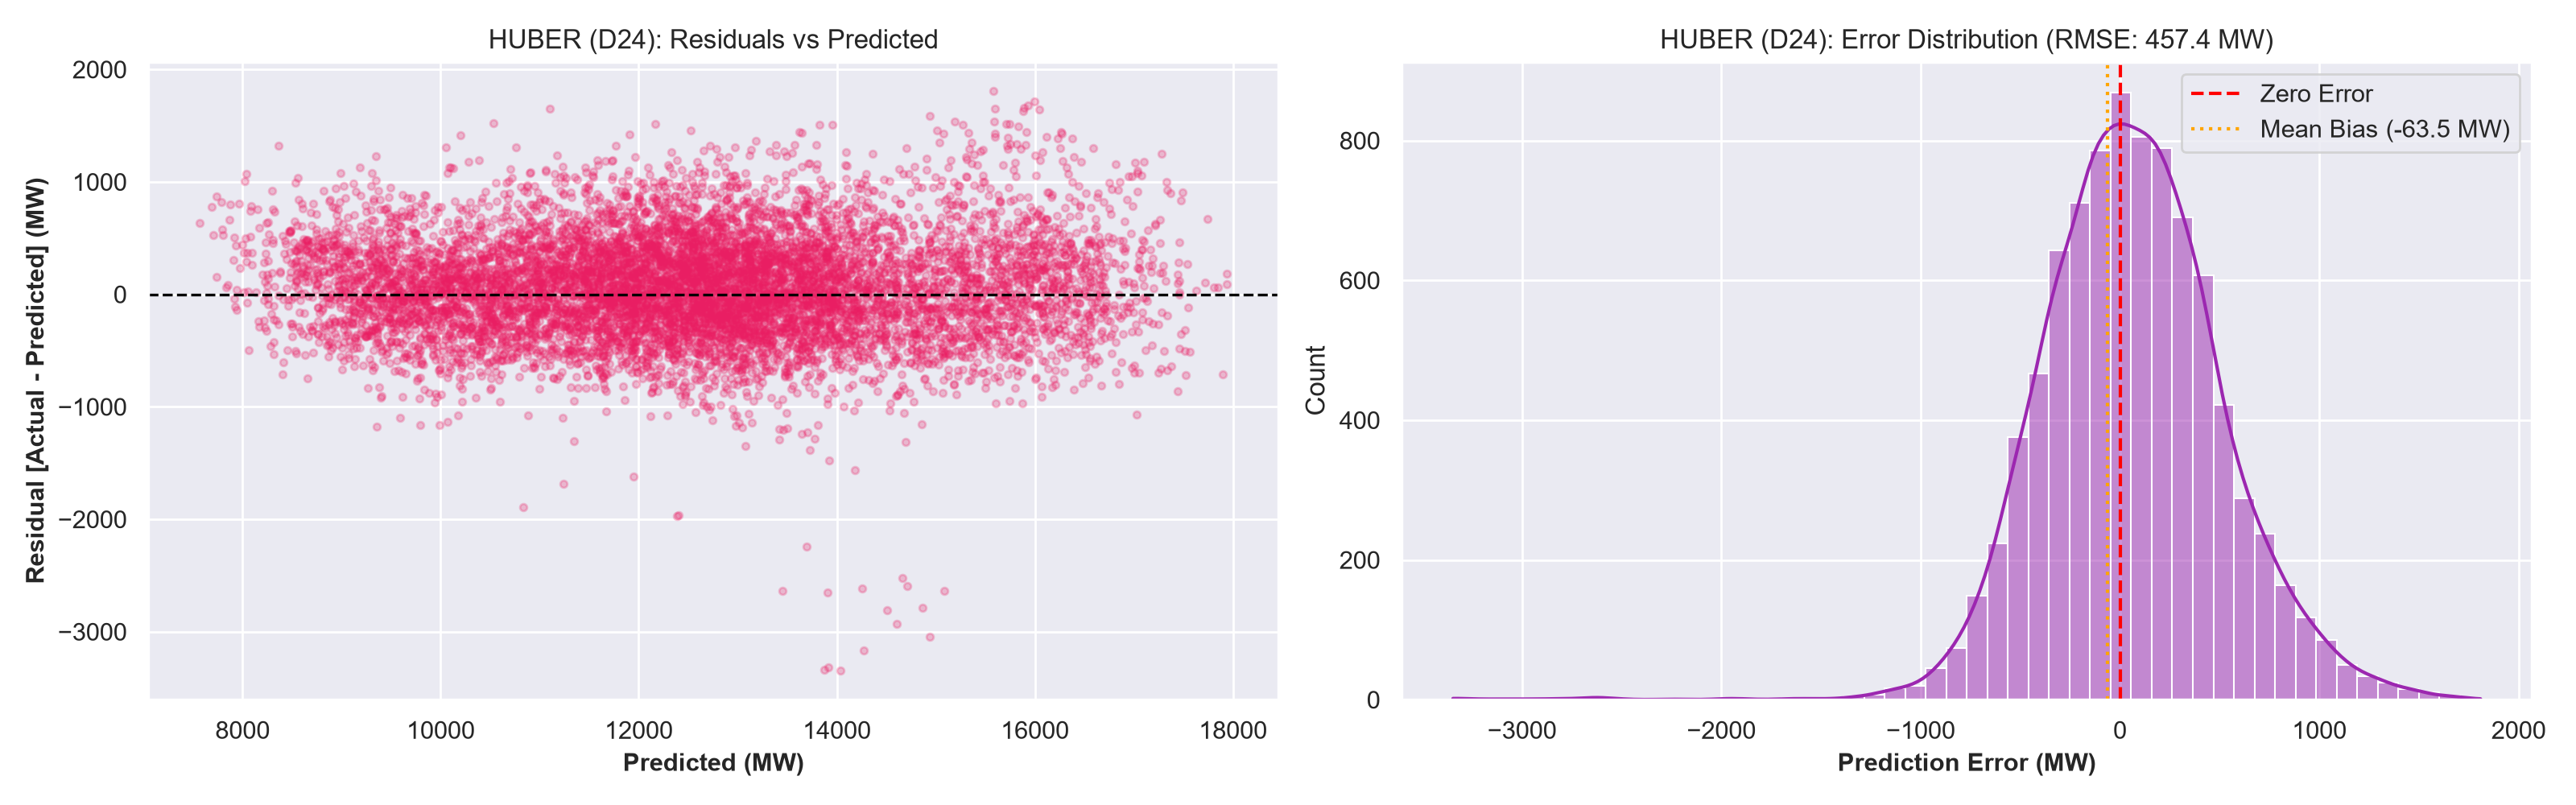

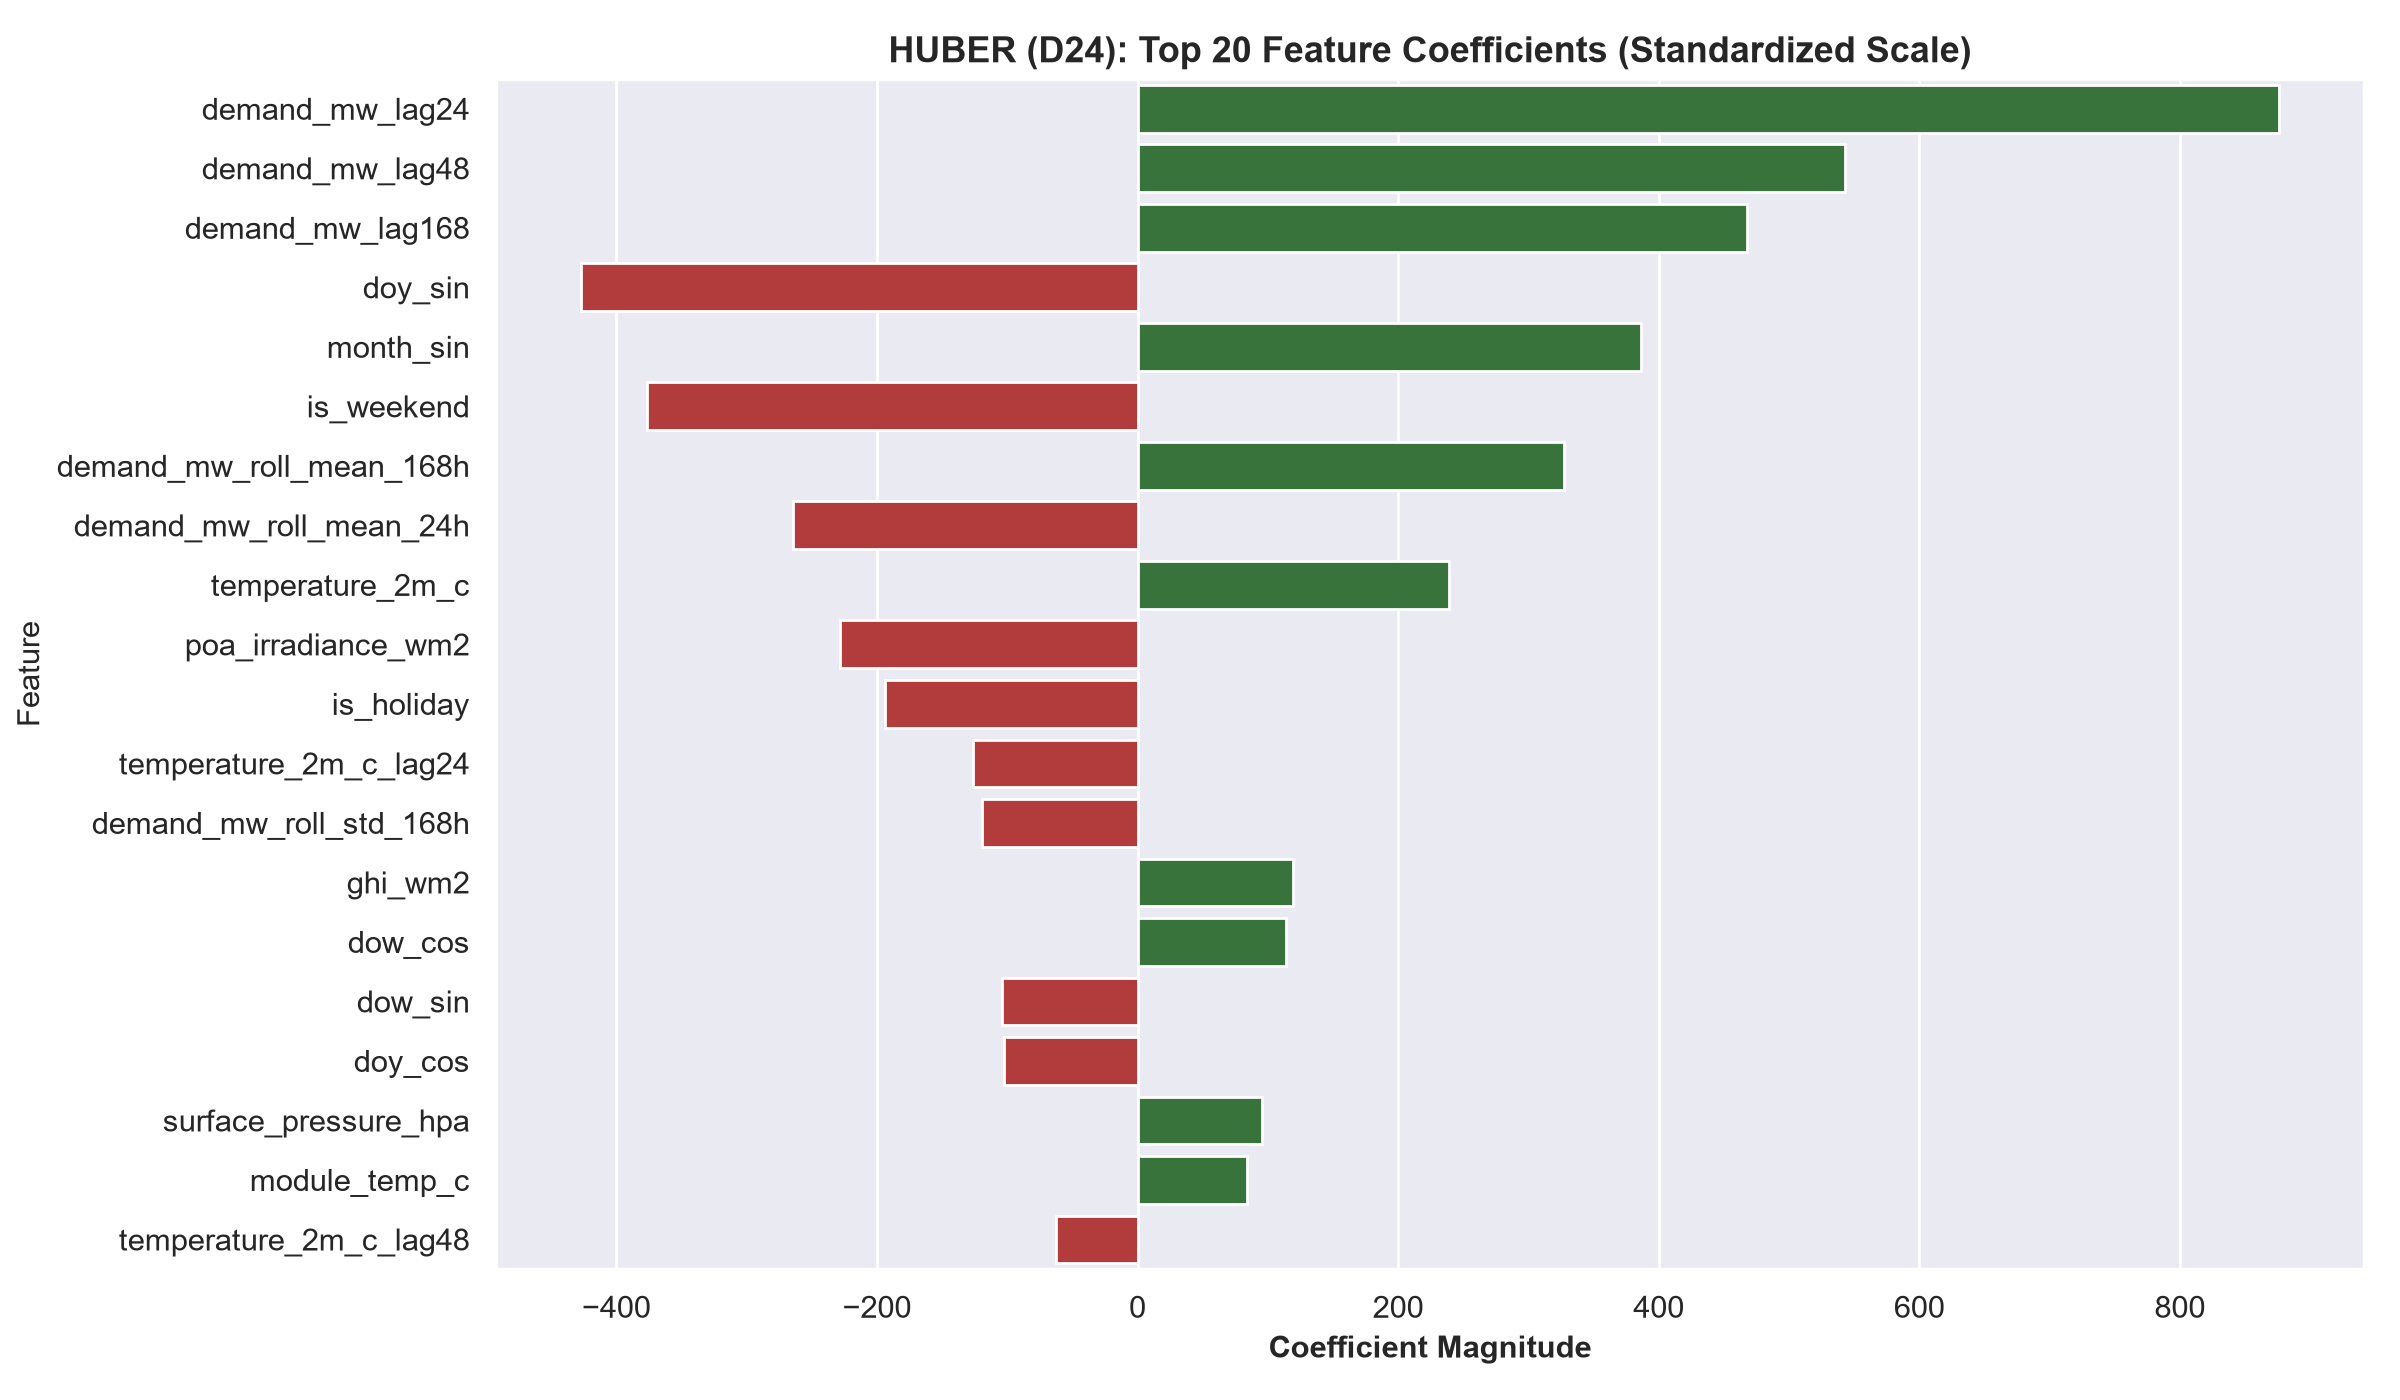

In [4]:
for pid in problems:
    print(f"\n======================================================================\nDIAGNOSTIC PLOTS FOR PROBLEM {pid}\n======================================================================")
    fig_actual = config.FIGURES_LINEAR_DIR / f"huber_{pid}_actual_vs_predicted.png"
    fig_resid = config.FIGURES_LINEAR_DIR / f"huber_{pid}_residuals_distribution.png"
    fig_coef = config.FIGURES_LINEAR_DIR / f"huber_{pid}_coefficients.png"
    
    if fig_actual.exists():
        display(Image(filename=str(fig_actual)))
    if fig_resid.exists():
        display(Image(filename=str(fig_resid)))
    if fig_coef.exists():
        display(Image(filename=str(fig_coef)))


## 4. Key Takeaways & Physics Interpretations
1. **Model Weights & Significance**:
   - For solar generation ($S_1, S_24$), Plane-of-Array irradiance (`poa_irradiance_wm2`) and recent lags carry the highest positive coefficients, while PV module temperature (`module_temp_c`) exhibits a negative coefficient consistent with the silicon thermal derating penalty.
   - For grid demand ($D_1, D_24$), diurnal lag ($t-24$), weekly lag ($t-168$), and ambient temperature (`temperature_2m_c`) dominate load forecasting accuracy.
2. **Persistence Benchmark**:
   - Compare the Skill Score column against the 0.0% baseline floor from Milestone M5. Positive skill scores demonstrate predictive value added by feature engineering.
